# DS223 - HW1

#Elya Hovsepyan

##AST SpaceMobile BlueBird

# Importing Libraries and Data

In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [80]:
df = pd.read_csv("API_IT.CEL.SETS_DS2_en_csv_v2_7178.csv",skiprows=4)

df.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,Mobile cellular subscriptions,IT.CEL.SETS,0.0,NaN,NaN,NaN,NaN,0.0,...,NaN,NaN,141000.0,141000.0,141000.0,140815.0,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Mobile cellular subscriptions,IT.CEL.SETS,0.0,NaN,NaN,NaN,NaN,0.0,...,406400000.0,428800000.0,458700000.0,486000000.0,533000000.0,568000000.0,617000000.0,672000000.0,734000000.0,NaN
2,Afghanistan,AFG,Mobile cellular subscriptions,IT.CEL.SETS,0.0,NaN,NaN,NaN,NaN,0.0,...,23929713.0,21976355.0,22580071.0,22678024.0,22678024.0,22831896.0,23027082.0,25630751.0,NaN,NaN
3,Africa Western and Central,AFW,Mobile cellular subscriptions,IT.CEL.SETS,0.0,NaN,NaN,NaN,NaN,0.0,...,358800000.0,397100000.0,423100000.0,459000000.0,462000000.0,508000000.0,516000000.0,479000000.0,462000000.0,NaN
4,Angola,AGO,Mobile cellular subscriptions,IT.CEL.SETS,0.0,NaN,NaN,NaN,NaN,0.0,...,13323952.0,13288421.0,14830154.0,14645050.0,15327864.0,23733217.0,25744029.0,26407932.0,NaN,NaN


In [81]:
df.columns

Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
       '2023', '2024', '2025', 'Unnamed: 70'],
      dtype='object')

In [82]:
world = df[df["Country Name"] == "World"].copy()

world

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
259,World,WLD,Mobile cellular subscriptions,IT.CEL.SETS,0.0,NaN,NaN,NaN,NaN,0.0,...,7.696600e+09,7.915300e+09,8.214200e+09,8.260000e+09,8.476000e+09,8.654000e+09,8.877000e+09,9.005000e+09,9.171000e+09,NaN


# Data Preparation

In [83]:
# Extracting the World data and converting it from wide format to a time series

years = [str(year) for year in range(1960, 2026)]

world_data = world[years].T
world_data.columns = ["subscriptions"]

world_data.index = world_data.index.astype(int)

# Remove years where there no data
world_data = world_data.dropna()

world_data.head(20)

,subscriptions
1960,0.0
1965,0.0
1970,0.0
1975,0.0
1976,0.0
1977,0.0
1978,0.0
1979,0.0
1980,23482.0
1981,63585.0


In [84]:
world_data.tail(10)

,subscriptions
2016,7.452200e+09
2017,7.696600e+09
2018,7.915300e+09
2019,8.214200e+09
2020,8.260000e+09
2021,8.476000e+09
2022,8.654000e+09
2023,8.877000e+09
2024,9.005000e+09
2025,9.171000e+09


In [85]:
# Showing the first years with actual mobile subscription data

world_data[world_data["subscriptions"] > 0].head(20)

,subscriptions
1980,23482.0
1981,63585.0
1982,101509.0
1983,148855.0
1984,319252.0
1985,750629.0
1986,1450136.0
1987,2545270.0
1988,4327956.0
1989,7353071.0


In [86]:
world_data.loc[1980:2010]

,subscriptions
1980,2.348200e+04
1981,6.358500e+04
1982,1.015090e+05
1983,1.488550e+05
1984,3.192520e+05
1985,7.506290e+05
1986,1.450136e+06
1987,2.545270e+06
1988,4.327956e+06
1989,7.353071e+06


# Adoption Graph

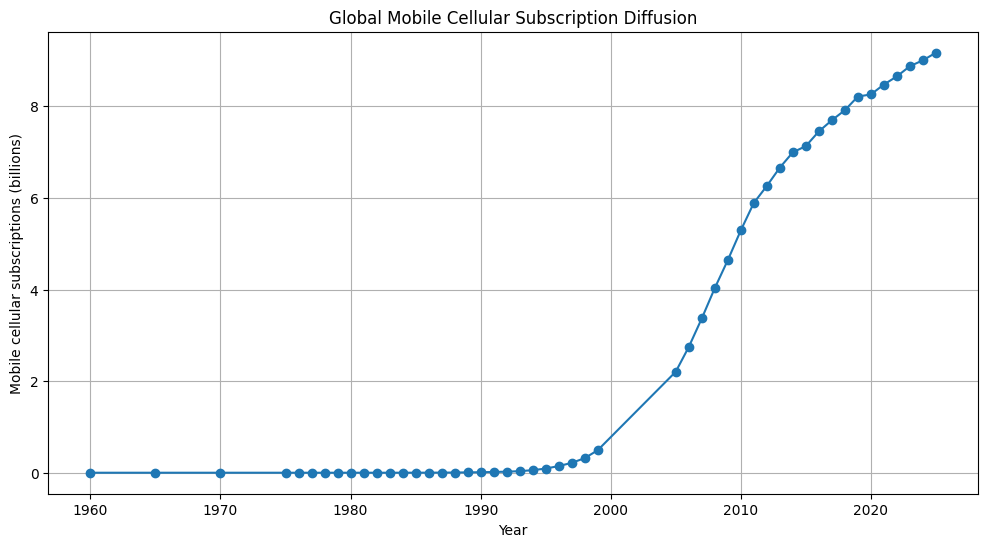

In [87]:
plt.figure(figsize=(12, 6))

plt.plot(
    world_data.index,
    world_data["subscriptions"] / 1e9,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Mobile cellular subscriptions (billions)")
plt.title("Global Mobile Cellular Subscription Diffusion")
plt.grid(True)

plt.show()

In [88]:
world_data.loc[1990:2025].describe()

,subscriptions
count,3.100000e+01
mean,4.527040e+09
std,3.542673e+09
min,1.121012e+07
25%,2.665254e+08
50%,5.290100e+09
75%,7.805950e+09
max,9.171000e+09


In [89]:
# Select the historical diffusion period
bass_data = world_data.loc[1985:2025].copy()

# Convert subscriptions to billions for easier interpretation
bass_data["adopters"] = bass_data["subscriptions"] / 1e9

# Create time index
bass_data["t"] = bass_data.index - 1984

bass_data.head()

,subscriptions,adopters,t
1985,750629.0,0.000751,1
1986,1450136.0,0.001450,2
1987,2545270.0,0.002545,3
1988,4327956.0,0.004328,4
1989,7353071.0,0.007353,5


In [90]:
bass_data.tail()

,subscriptions,adopters,t
2021,8.476000e+09,8.476,37
2022,8.654000e+09,8.654,38
2023,8.877000e+09,8.877,39
2024,9.005000e+09,9.005,40
2025,9.171000e+09,9.171,41


In [91]:
bass_data.loc[1999:2005]

,subscriptions,adopters,t
1999,4.909842e+08,0.490984,15
2005,2.205300e+09,2.205300,21


In [92]:
world[["1999", "2000", "2001", "2002", "2003", "2004", "2005"]].T

,259
1999,4.909842e+08
2000,NaN
2001,NaN
2002,NaN
2003,NaN
2004,NaN
2005,2.205300e+09


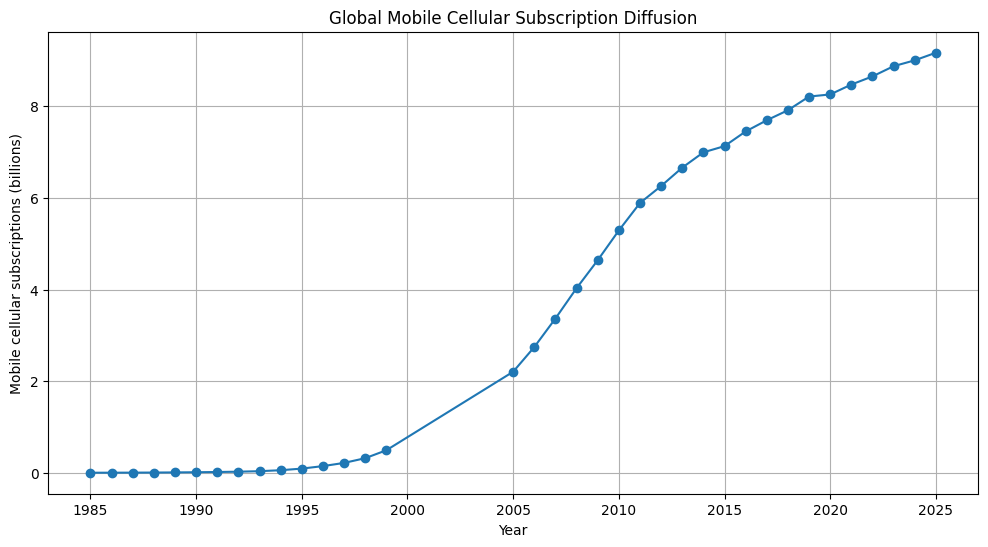

In [93]:
plt.figure(figsize=(12, 6))

plt.plot(
    bass_data.index,
    bass_data["adopters"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Mobile cellular subscriptions (billions)")
plt.title("Global Mobile Cellular Subscription Diffusion")
plt.grid(True)

plt.show()

In [94]:
bass_data.tail(10)

,subscriptions,adopters,t
2016,7.452200e+09,7.4522,32
2017,7.696600e+09,7.6966,33
2018,7.915300e+09,7.9153,34
2019,8.214200e+09,8.2142,35
2020,8.260000e+09,8.2600,36
2021,8.476000e+09,8.4760,37
2022,8.654000e+09,8.6540,38
2023,8.877000e+09,8.8770,39
2024,9.005000e+09,9.0050,40
2025,9.171000e+09,9.1710,41


# Yearly New Subscriptions

In [95]:
bass_data["new_adopters"] = bass_data["adopters"].diff()

bass_data.tail(10)

,subscriptions,adopters,t,new_adopters
2016,7.452200e+09,7.4522,32,0.3205
2017,7.696600e+09,7.6966,33,0.2444
2018,7.915300e+09,7.9153,34,0.2187
2019,8.214200e+09,8.2142,35,0.2989
2020,8.260000e+09,8.2600,36,0.0458
2021,8.476000e+09,8.4760,37,0.2160
2022,8.654000e+09,8.6540,38,0.1780
2023,8.877000e+09,8.8770,39,0.2230
2024,9.005000e+09,9.0050,40,0.1280
2025,9.171000e+09,9.1710,41,0.1660


# Estimate M, p, q

In [96]:
from scipy.optimize import curve_fit

def bass_model(t, M, p, q):
    return M * (
        (1 - np.exp(-(p + q) * t)) /
        (1 + (q / p) * np.exp(-(p + q) * t)))

In [97]:
fit_data = bass_data.dropna(subset=["adopters"]).copy()

t_data = fit_data["t"].values
N_data = fit_data["adopters"].values

In [98]:
initial_guess = [10, 0.01, 0.15]

params, covariance = curve_fit(
    bass_model,
    t_data,
    N_data,
    p0=initial_guess,
    bounds=([9.18, 0.0001, 0.0001],
            [20, 1, 2]),
    maxfev=10000
)

M_fit, p_fit, q_fit = params

print(f"M = {M_fit:.4f} billion")
print(f"p = {p_fit:.6f}")
print(f"q = {q_fit:.6f}")

M = 9.1800 billion
p = 0.000542
q = 0.241235


In [99]:
parameter_results = pd.DataFrame({
    "Parameter": ["M", "p", "q"],
    "Value": [M_fit, p_fit, q_fit]
})

parameter_results

,Parameter,Value
0,M,9.180000
1,p,0.000542
2,q,0.241235


\(M\) represents the estimated market potential, \(p\) represents adoption caused by external influences, and \(q\) represents adoption influenced by existing adopters and imitation effects.

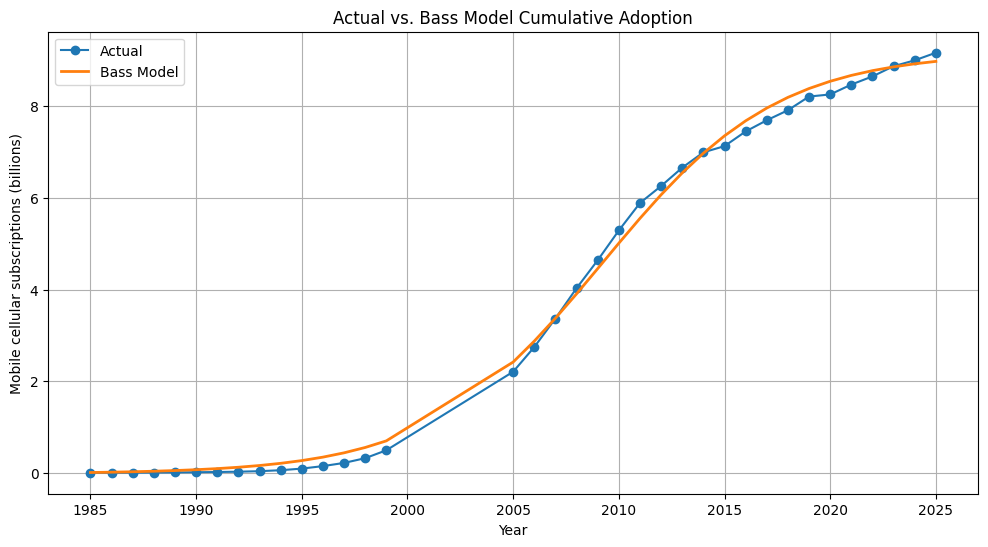

In [100]:
# Calculate Bass model fitted values
fit_data["predicted_adopters"] = bass_model(
    fit_data["t"],
    M_fit,
    p_fit,
    q_fit
)

# Plot actual vs fitted cumulative adoption
plt.figure(figsize=(12, 6))

plt.plot(
    fit_data.index,
    fit_data["adopters"],
    marker="o",
    label="Actual"
)

plt.plot(
    fit_data.index,
    fit_data["predicted_adopters"],
    linewidth=2,
    label="Bass Model"
)

plt.xlabel("Year")
plt.ylabel("Mobile cellular subscriptions (billions)")
plt.title("Actual vs. Bass Model Cumulative Adoption")
plt.legend()
plt.grid(True)

plt.show()

In [101]:
# Calculate R², MAE, and RMSE for the direct Bass fit

actual = fit_data["adopters"]
predicted = fit_data["predicted_adopters"]

ss_res = np.sum((actual - predicted) ** 2)
ss_tot = np.sum((actual - actual.mean()) ** 2)

r2_bass = 1 - ss_res / ss_tot

mae_bass = np.mean(np.abs(actual - predicted))

rmse_bass = np.sqrt(np.mean((actual - predicted) ** 2))

print(f"R² = {r2_bass:.4f}")
print(f"MAE = {mae_bass:.4f} billion subscriptions")
print(f"RMSE = {rmse_bass:.4f} billion subscriptions")

R² = 0.9977
MAE = 0.1472 billion subscriptions
RMSE = 0.1739 billion subscriptions


# Predicting Diffusion of Innovation

Forecasting assumption:
Since BlueBird is a new technology without sufficient historical adoption data, we use the \(p\) and \(q\) coefficients estimated from global mobile cellular subscription diffusion as a benchmark. This assumes that BlueBird's adoption dynamics will be broadly similar to those of mobile cellular connectivity. Therefore, the forecast should be interpreted as a scenario estimate rather than an exact commercial prediction.

BlueBird market potential assumption:
We assume a market potential of 5.8 billion users for BlueBird. AST SpaceMobile states that approximately 5.8 billion mobile users move in and out of cellular coverage every day. This value is therefore used as an estimate of BlueBird's addressable market, rather than assuming that all 5.8 billion users will necessarily adopt the service.

In [102]:
p_bluebird = p_fit
q_bluebird = q_fit
M_bluebird = 5.8  # billion potential users

In [103]:
# BlueBird diffusion forecast
years_bluebird = np.arange(2025, 2041)

t_bluebird = years_bluebird - 2025

bluebird_adoption = bass_model(
    t_bluebird,
    M_bluebird,
    p_bluebird,
    q_bluebird
)

bluebird_forecast = pd.DataFrame({
    "year": years_bluebird,
    "t": t_bluebird,
    "cumulative_adopters": bluebird_adoption
})

bluebird_forecast["new_adopters"] = (
    bluebird_forecast["cumulative_adopters"].diff()
)

bluebird_forecast

,year,t,cumulative_adopters,new_adopters
0,2025,0,0.000000,NaN
1,2026,1,0.003556,0.003556
2,2027,2,0.008079,0.004523
3,2028,3,0.013829,0.005750
4,2029,4,0.021134,0.007306
5,2030,5,0.030411,0.009277
6,2031,6,0.042183,0.011771
7,2032,7,0.057104,0.014922
8,2033,8,0.075995,0.018891
9,2034,9,0.099875,0.023879


Using the estimated Bass parameters from the historical mobile cellular subscription data (\(p=0.000542\), \(q=0.241235\)) and an assumed BlueBird market potential of 5.8 billion users, the Bass model predicts gradual initial adoption followed by accelerating diffusion. By 2030, cumulative adoption is approximately 30.4 million users, increasing to approximately 130 million by 2035 and 440 million by 2040. The increasing number of new adopters per year reflects the imitation effect represented by \(q\).

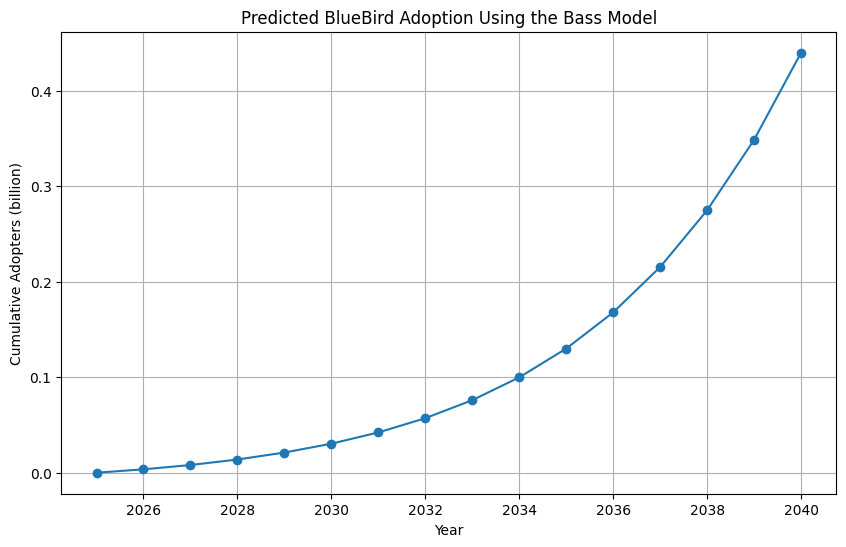

In [104]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    bluebird_forecast["year"],
    bluebird_forecast["cumulative_adopters"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Cumulative Adopters (billion)")
plt.title("Predicted BlueBird Adoption Using the Bass Model")
plt.grid(True)

plt.show()

# Point 6: Choosing Scope

## Selected Innovation and Historical Look-Alike

**Selected innovation:** AST SpaceMobile BlueBird

**TIME Best Inventions 2025:**  
https://time.com/collections/best-inventions-2025/7318228/ast-spacemobile-bluebird/

**Historical look-alike:** Mobile cellular networks/subscriptions

Mobile cellular subscriptions were selected as the historical look-alike because both technologies provide wireless connectivity to mobile users. Their adoption can be represented through subscriber numbers, making mobile cellular diffusion a suitable historical benchmark for the Bass model.

**Historical data source:** World Bank / ITU – Mobile cellular subscriptions  
https://data.worldbank.org/indicator/IT.CEL.SETS



Scope: Global


We use a global scope because both the historical look-alike (mobile cellular subscriptions) and AST SpaceMobile's BlueBird technology are designed for international markets. AST SpaceMobile describes its goal as providing cellular broadband connectivity to mobile users beyond the reach of traditional cell towers, with its next-generation BlueBird satellites intended to provide global coverage. Therefore, global mobile subscription data provides the most appropriate basis for estimating the diffusion of BlueBird.

**Source:** AST SpaceMobile – SpaceMobile Network  
https://ast-science.com/spacemobile-network/

**Source:** AST SpaceMobile – Next-Generation BlueBird  
https://ast-science.com/next-gen-bluebird/

# Estimate of the N of Adopters by Period

In [105]:
main_results = bluebird_forecast[
    bluebird_forecast["year"].isin([2025, 2030, 2035, 2040])
].copy()

main_results["cumulative_adopters_millions"] = (
    main_results["cumulative_adopters"] * 1000
).round(1)

main_results["new_adopters_millions"] = (
    main_results["new_adopters"] * 1000
).round(1)

main_results[
    ["year", "cumulative_adopters_millions", "new_adopters_millions"]
]

,year,cumulative_adopters_millions,new_adopters_millions
0,2025,0.0,NaN
5,2030,30.4,9.3
10,2035,130.0,30.1
15,2040,439.9,91.2


# Conclusion

The Bass model was fitted to global mobile cellular subscription data to estimate the parameters \(M\), \(p\), and \(q\). These parameters were then used as a benchmark to forecast the diffusion of AST SpaceMobile's BlueBird technology. Under the assumed global market potential of 5.8 billion users, the model predicts approximately 30.4 million cumulative adopters by 2030, 130.0 million by 2035, and 439.9 million by 2040. These results should be interpreted as a scenario estimate because BlueBird is a new technology and its actual adoption dynamics may differ from historical mobile cellular diffusion.